<h2 style="color:fuchsia; font-family:; text-align:center;font-size:35px">
  ❁۪ ｡˚ Random Forests and Photo-zs  ❁۪ ｡˚
</h2>
En este notebook, se usa el algoritmo de random forest para estimar redshifts fotométricos a partir de observaciones de galaxias en 6 filtros diferentes  (u, g, r, i, z, y).

Basado en Machine learning for physics and Astronomy, Viviana Acquaviva (2023)

Trataremos de reproducir los resultados de [Zhou et. al. 2019](https://academic.oup.com/mnras/article/488/4/4565/5538813)

In [503]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rc
from sklearn.svm import SVC, LinearSVC # Nuevo algoritmo!
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_predict, cross_validate
from sklearn.model_selection import KFold, StratifiedKFold
from sklearn import metrics
from sklearn.model_selection import GridSearchCV # Nuevo! Para explorar los hiperparámetros del modelo

In [504]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', 100)


font = {'size'   : 16}
matplotlib.rc('font', **font)
matplotlib.rc('xtick', labelsize=14) 
matplotlib.rc('ytick', labelsize=14) 
matplotlib.rcParams.update({'figure.autolayout': False})
matplotlib.rcParams['figure.dpi'] = 300

In [505]:
from sklearn import metrics
from sklearn.model_selection import cross_validate, KFold, cross_val_predict, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor

In [506]:
#!pip install astropy
import astropy

from astropy.io import fits

#### Importamos los datos

Leemos el archivo fits y lo leemos usando pandas

In [507]:
with fits.open('DEEP2_uniq_Terapix_Subaru_v1.fits') as data:
    df = pd.DataFrame(np.array(data[1].data).byteswap().newbyteorder()) 
    #https://numpy.org/doc/2.1/user/byteswapping.html

In [508]:
df.columns

Index(['objno_deep2', 'ra_deep2', 'dec_deep2', 'magb', 'magr', 'magi', 'pgal',
       'sfd_ebv', 'class', 'subclass', 'objname', 'maskname', 'slitname',
       'date', 'mjd', 'z_raw', 'zhelio', 'z_err', 'rchi2', 'dof', 'vdisp',
       'vdisp_err', 'zquality', 'egsflags', 'comment', 'm_b', 'ub_0',
       'ra_cfhtls', 'dec_cfhtls', 'u', 'g', 'r', 'i', 'i2', 'z', 'uerr',
       'gerr', 'rerr', 'ierr', 'i2err', 'zerr', 'u_apercor', 'g_apercor',
       'r_apercor', 'i_apercor', 'i2_apercor', 'z_apercor', 'uerr_aper',
       'gerr_aper', 'rerr_aper', 'ierr_aper', 'i2err_aper', 'zerr_aper',
       'uerr_apercor', 'gerr_apercor', 'rerr_apercor', 'ierr_apercor',
       'i2err_apercor', 'zerr_apercor', 'r_radius_arcsec', 'u(sexflag)',
       'g(sexflag)', 'r(sexflag)', 'i(sexflag)', 'i2(sexflag)', 'z(sexflag)',
       'flag_cfhtls', 'cfhtls_source', 'ra_subaru', 'dec_subaru', 'y', 'yerr',
       'y_apercor', 'yerr_aper', 'yerr_apercor', 'y(sexflag)',
       'y_radius_arcsec', 'subaru_source'],
 

In [509]:
df.head()

,objno_deep2,ra_deep2,dec_deep2,magb,magr,magi,pgal,sfd_ebv,class,subclass,objname,maskname,slitname,date,mjd,z_raw,zhelio,z_err,rchi2,dof,vdisp,vdisp_err,zquality,egsflags,comment,m_b,ub_0,ra_cfhtls,dec_cfhtls,u,g,r,i,i2,z,uerr,gerr,rerr,ierr,i2err,zerr,u_apercor,g_apercor,r_apercor,i_apercor,i2_apercor,z_apercor,uerr_aper,gerr_aper,rerr_aper,ierr_aper,i2err_aper,zerr_aper,uerr_apercor,gerr_apercor,rerr_apercor,ierr_apercor,i2err_apercor,zerr_apercor,r_radius_arcsec,u(sexflag),g(sexflag),r(sexflag),i(sexflag),i2(sexflag),z(sexflag),flag_cfhtls,cfhtls_source,ra_subaru,dec_subaru,y,yerr,y_apercor,yerr_aper,yerr_apercor,y(sexflag),y_radius_arcsec,subaru_source
0,11001673,213.868704,51.956445,23.487745,23.143082,22.582092,1.000000,0.010943,b'',b'',b'11001673',b'1101',b'000',b'2003-05-06',52765.457031,1.115297,1.115261,999.900024,0.630934,57.0,999.900024,999.900024,2,16777216,"b'bext, bcol, possible OII'",-999.000000,-999.0000,213.868620,51.956434,23.529039,23.393115,23.148170,22.854212,-99.0,22.162377,0.0678,0.0400,0.0382,0.0678,-99.0,0.0623,23.543491,23.430495,23.100311,22.768970,-99.0,22.223810,0.0542,0.0323,0.0279,0.0466,-99.0,0.0536,0.039631,0.041359,0.039777,0.046863,-99.0,0.043833,0.581804,3,3,3,3,-99,3,0,1,213.868626,51.956443,21.869627,0.060918,21.926356,0.041955,0.141778,3.0,0.656514,1
1,11001699,213.810471,51.942316,22.067692,20.034674,19.545080,3.000000,0.011014,b'GALAXY',b'',b'11001699',b'1100',b'7',b'2003-05-03',52762.441406,0.290641,0.290608,0.000043,1.178153,5901.0,166.334991,49.481255,4,16777216,b'',-19.228701,1.1295,213.810138,51.942348,30.123756,28.298480,18.540350,99.000000,-99.0,99.000000,0.0000,0.0000,0.0014,99.0000,-99.0,99.0000,30.848978,28.989668,19.027422,99.000000,-99.0,99.000000,0.0000,0.0000,0.0028,99.0000,-99.0,99.0000,0.029567,0.030353,0.027558,99.000000,-99.0,99.000000,0.824625,19,19,19,3,-99,3,244,1,213.810455,51.942321,18.757229,0.005813,18.811085,0.004386,0.050987,3.0,0.744269,1
2,11001770,213.848431,51.948876,24.144438,24.103180,24.020006,3.000000,0.010856,b'GALAXY',b'',b'11001770',b'1101',b'003',b'2003-05-06',52765.457031,0.605779,0.605744,-5.000000,1.047260,5318.0,184.860001,195.000000,1,16777216,b'',-999.000000,-999.0000,213.848409,51.948865,24.294289,24.399293,24.413366,23.398456,-99.0,24.157690,0.1646,0.1383,0.2306,0.1867,-99.0,0.4558,24.324670,24.273606,24.150319,23.446252,-99.0,23.574236,0.1146,0.0870,0.1242,0.1309,-99.0,0.1793,0.111127,0.130134,0.123620,0.117813,-99.0,0.101059,0.728119,0,0,0,0,-99,0,0,1,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.0,-99.000000,-99
3,11001800,213.831758,51.952548,25.336836,23.508480,23.081087,0.509809,0.010823,b'GALAXY',b'',b'11001800',b'1100',b'004',b'2003-05-03',52762.441406,1.306830,1.306796,-5.000000,1.014062,5788.0,0.000000,0.000000,1,16777216,b'',-999.000000,-999.0000,213.831785,51.952539,26.363821,24.530998,23.559140,23.065110,-99.0,22.737333,0.9609,0.1344,0.0648,0.0997,-99.0,0.1110,99.000000,24.804309,23.636544,23.009222,-99.0,22.689591,99.0000,0.1077,0.0426,0.0568,-99.0,0.0661,99.000000,0.046521,0.041142,0.054297,-99.0,0.053818,0.549061,0,0,0,0,-99,0,0,1,213.831766,51.952544,22.404269,0.088970,22.535600,0.053497,0.094733,0.0,0.455820,1
4,11001860,213.832550,51.954174,24.382738,23.401484,22.572845,3.000000,0.010827,b'GALAXY',b'',b'11001860',b'1101',b'10',b'2003-05-06',52765.457031,0.957705,0.957669,0.000099,1.039979,5952.0,109.394997,17.208755,4,16777216,b'',-20.083200,0.7524,213.832540,51.954167,24.571406,24.023086,23.493832,22.691404,-99.0,22.387428,0.1924,0.0874,0.0651,0.0715,-99.0,0.0850,24.362068,24.136913,23.490342,22.777181,-99.0,22.319676,0.1002,0.0615,0.0420,0.0473,-99.0,0.0508,0.050326,0.053198,0.052364,0.058492,-99.0,0.053587,0.595684,0,0,0,0,-99,0,0,1,213.832574,51.954175,22.242717,0.070760,22.100980,0.033256,0.073067,0.0,0.442022,1


In [510]:
df.shape

(23822, 78)

Seleccione las columnas que contienen el brillo de las galaxias en los 6 filtros de interés, 'u,g,r,i,z,y' (con sufijo 'apercor') como las características y el redshift (espectroscópico) como la variable a predecir (`zhelio`)

In [511]:
features=["u_apercor", "g_apercor", "r_apercor", "i_apercor", "z_apercor","y_apercor"]
F = df[features]

In [512]:
df[features].head(13)

,u_apercor,g_apercor,r_apercor,i_apercor,z_apercor,y_apercor
0,23.543491,23.430495,23.100311,22.768970,22.223810,21.926356
1,30.848978,28.989668,19.027422,99.000000,99.000000,18.811085
2,24.324670,24.273606,24.150319,23.446252,23.574236,-99.000000
3,99.000000,24.804309,23.636544,23.009222,22.689591,22.535600
4,24.362068,24.136913,23.490342,22.777181,22.319676,22.100980
5,23.552186,23.420734,23.010863,22.550723,22.277656,21.860866
6,23.983330,24.104438,23.461145,23.359428,22.929944,22.690175
7,24.665840,24.408938,23.544115,23.155140,22.706477,22.894691
8,23.518039,22.746858,21.571629,20.645176,20.428926,20.306110
9,22.755723,21.915841,21.393365,21.148952,21.052236,20.830114


In [513]:
target=["zhelio"]
T=df[target]

### Ahora empezaremos a implementar nuestro modelo de Random Forest

Figura 5 del paper

 ![Performance of photometric redshift reconstruction](https://oup.silverchair-cdn.com/oup/backfile/Content_public/Journal/mnras/488/4/10.1093_mnras_stz1866/1/stz1866fig5.jpeg?Expires=1764255560&Signature=YsogBmQvQ0CkbNXBEimFc23Rt9Slq~Q5qJGdV1YfvS3w-Z3IEJvD7FrYcOoSm6U0xY-gU~5JqYe2A7wjaHjQ~GAPOIZP8Kod-zh~1sxPBUDM3aj4kio313nsCcC-zCJRDd1OEvPncis9N7puYcPeqj2R3rSNaGk4QJCOBtGhE5-NLbwFbQFalDhy7dELFeMm4uZQxaCwNeJF1NsQBETobU-LK13KulZ51tMrLF1HiDEjQetQBvccYAG6sC2fTWrNNtv9lSl9PEaac9qHSycwfyDc8GeHPFyh~DmL7KSQM3V1PEEkjG6-RYrwZaXYBorj5PkR9ZLJQzoNqRxn4Gl7rg__&Key-Pair-Id=APKAIE5G5CRDK6RD3PGA)

En la figura, $\sigma_{NMAD}$ es la [normalized median absolute deviation de los residuos](https://en.wikipedia.org/wiki/Median_absolute_deviation), definida como $\sigma_{NMAD}=1.48\cdot MAD$, donde $MAD = \text{median}(\frac{|\Delta z|}{(1 + zspec)})$, $\Delta z =z_{phot}-z_{spec}$  y $\eta$ es la fracción de outliers definido como los objetos que cumplen $|(\Delta z)| > 0.15\cdot(1+z_{spec})$


In [111]:
model = RandomForestRegressor()

In [112]:
model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 1.0,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

Empezaremos estableciendo un benchmark

Implemente el modelo de random forest definido arriba en esquema de validación cruzada KFold, reporte la métrica para entrenamiento y prueba. Recordemos que la métrica por defecto es $R^2$ ( se usa scoring r2)

In [113]:
#esto como para lo realizado en regresión en act5, pero ahora para clasificación
cv = KFold(n_splits=5, shuffle=True, random_state=101) #para la clasificación

In [114]:
%%time
scores = cross_validate(model,F,T,cv=cv,scoring="r2",return_train_score=True)

/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vec

CPU times: user 23.5 s, sys: 169 ms, total: 23.7 s
Wall time: 23.7 s


In [116]:
df_results = pd.DataFrame({"Fold": range(1, 6),"R2_train": scores["train_score"],"R2_test": scores["test_score"]})
display(df_results.round(4))
#Calculando el promedio y la desviación estándar de las métricas obtenidas.
#aqui busque como se podia hacer la forma de tabla involucrando datos de mean y std para los 5 splits
print(f"R² entrenamiento: {scores['train_score'].mean():.4f} "
      f"± {scores['train_score'].std():.4f}")
print(f"R² prueba:        {scores['test_score'].mean():.4f} "
      f"± {scores['test_score'].std():.4f}")

,Fold,R2_train,R2_test
0,1,0.8758,0.3152
1,2,0.8781,0.2885
2,3,0.8755,0.3269
3,4,0.8749,0.3290
4,5,0.8757,0.3092


R² entrenamiento: 0.8760 ± 0.0011
R² prueba:        0.3138 ± 0.0146


NO SE CONSIGUE AUN BUENA METRICA COMPARADO CON PAPER 
LA CALIDAD DE DATOS PARA ASEGURAR UN MODELO MEJOR
verificar el random forest y tratar de reproducir la métrica
EL MODELO REGRESION O DE CLASIFICACION CON EL ALGORITMO QUE QUERAMOS Y JUSTIFICADO

In [152]:
scores

{'fit_time': array([4.41668773, 4.40927529, 4.38020182, 4.41435075, 4.39299512]),
 'score_time': array([0.0777781 , 0.07744098, 0.07954311, 0.08109117, 0.07984686]),
 'test_score': array([0.3141832 , 0.29066908, 0.32886065, 0.33104104, 0.30250595]),
 'train_score': array([0.87547621, 0.87831958, 0.87494089, 0.87420635, 0.87578389])}

**Qué puede decir de este resultado? Hay bias alto o varianza alta?**

Puede comparar los valores reales con los predichos, generando las predicciones con `cross_val_predict`

In [153]:
#predicción realizada con datos no usados en train
ypred = cross_val_predict(model,F,T,cv=cv)

/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vec

(0.0, 3.0)

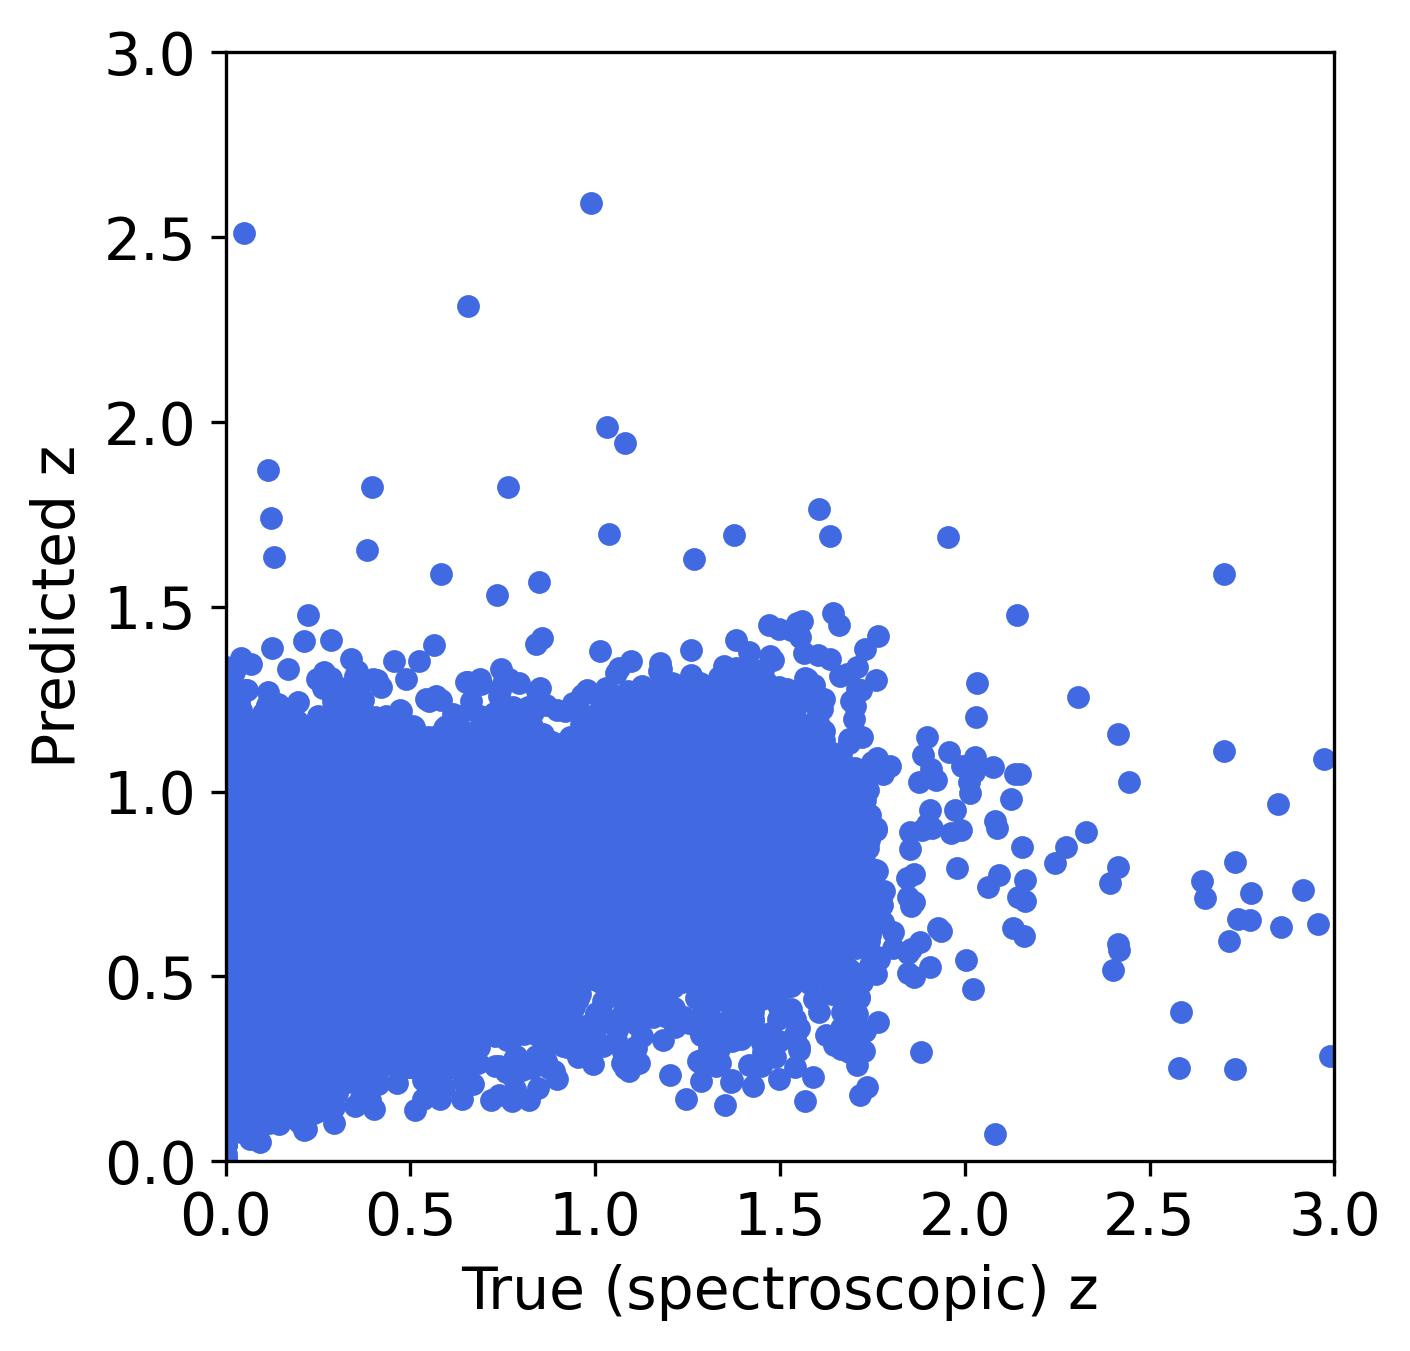

In [154]:
plt.scatter(T,ypred, s = 20, c = 'royalblue')
plt.xlabel('True (spectroscopic) z', fontsize=14)
plt.ylabel('Predicted z',fontsize=14)
plt.axis('square')
plt.xlim(0,3)
plt.ylim(0,3)

### Se parece al resultado del paper??

No se parece, dado que el resultado del paper tiene más pendiente y los datos están "más formaditos" hacia la misma.

También es interesante observar la distribución de los valores predichos, para ver cómo siempre tienden a producir una distribución más estrecha. 

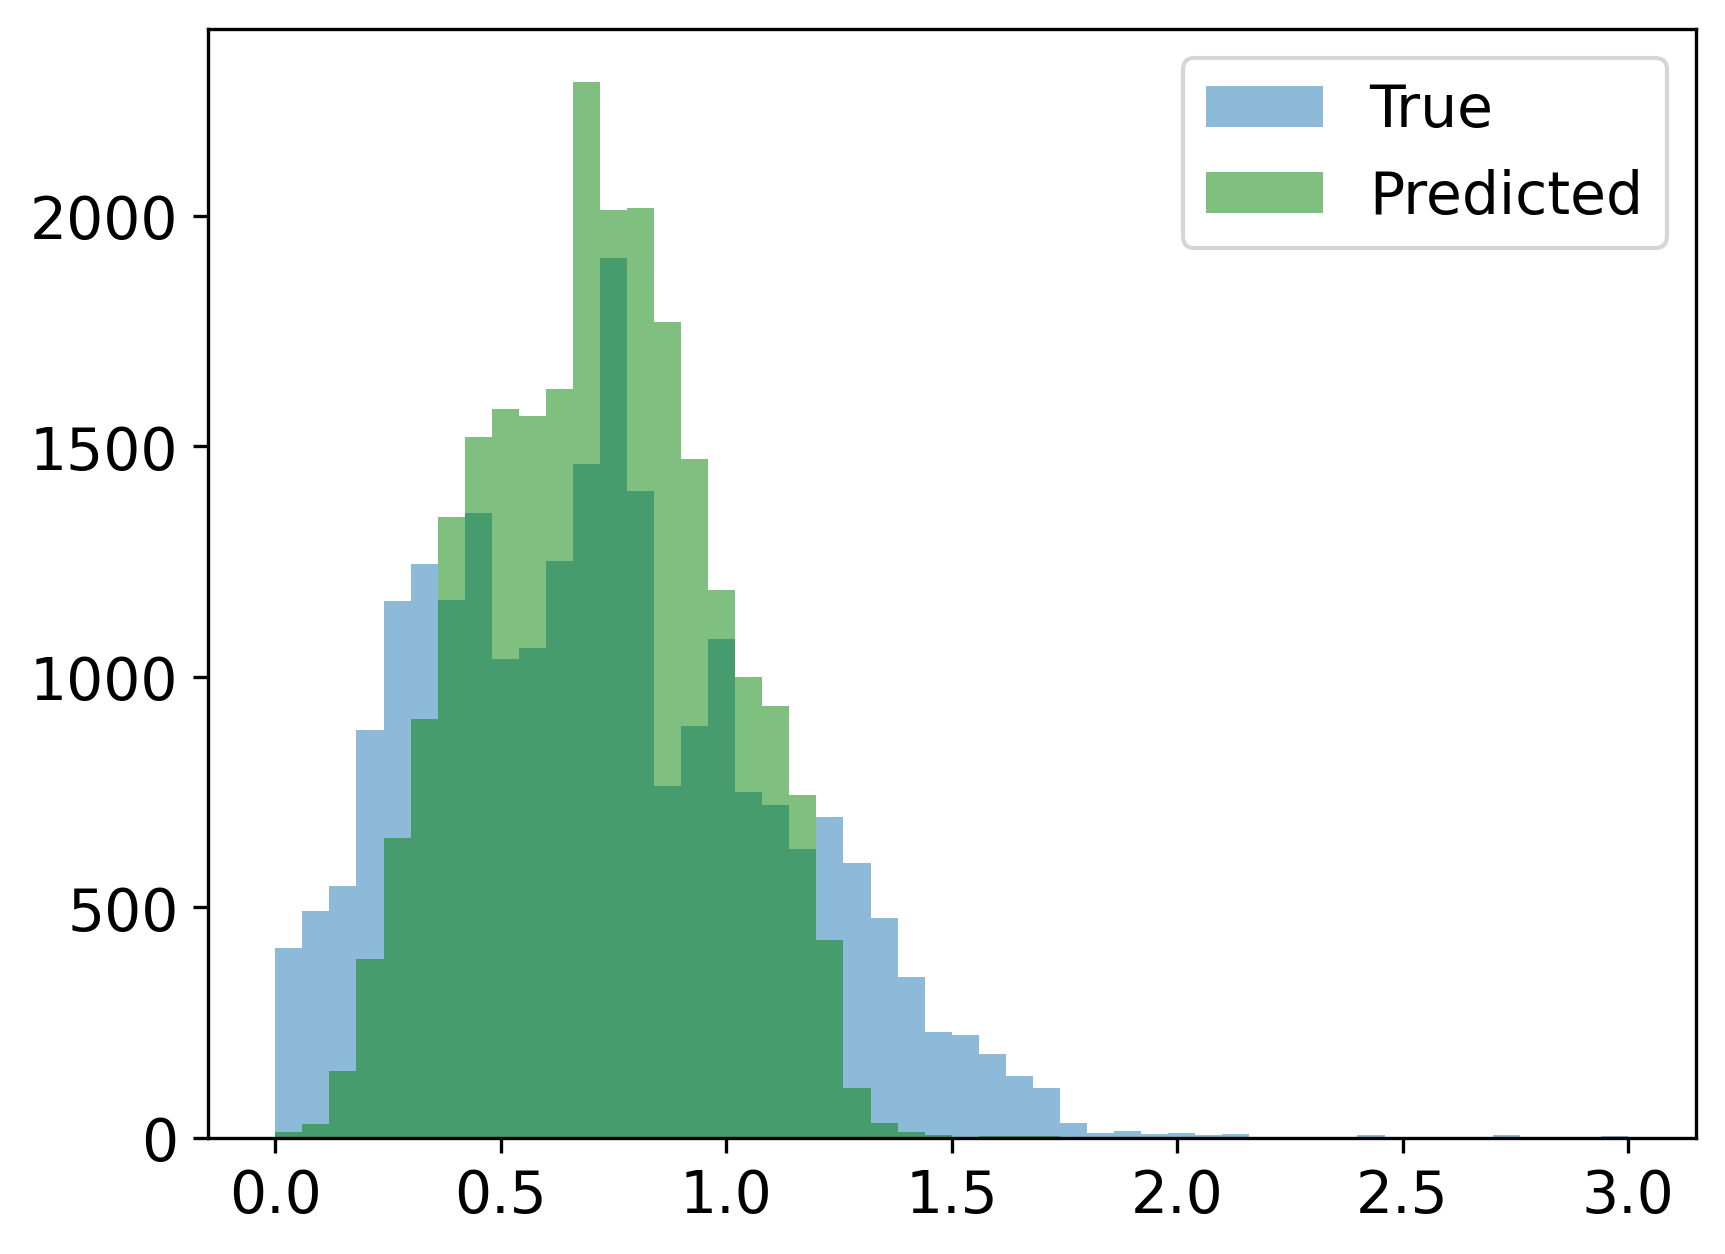

In [155]:
plt.hist(T,bins=50,density=False,alpha=0.5, range = (0,3), label = 'True');
plt.hist(ypred,bins=50,density=False,alpha=0.5, range = (0,3), color = 'g', label = 'Predicted');
plt.legend(fontsize=14);


<h2 style="color:fuchsia; font-family:; text-align:center;font-size:17px">
  ❁۪ ｡˚ Ahora calcule las métricas del paper; fracción de outliers $eta$ y $\sigma_{NMAD}$ y compare con los resultados del paper y NMAD ❁۪ ｡˚
</h2>

Two quantities are used to evaluate
the photo-z performance here: the normalized median absolute
deviation σNMAD = 1.48 MAD, where MAD= median(|z|/(1 +
zspec)), and the outlier fraction η which is defined as the fraction of
objects with |z| > 0.15/(1 + zspec).


Luego, el sigmaNMAD, es σNMAD = 1.48*median(|z|/(1 +zspec))
y el eta da como $eta$ = mean(abs(ok_z) > 0.15)  donde abs(ok_z) involucra toda la fracción encontrada F


PAPER: we achieve photo-z accuracy σNMAD = 0.018 and outlier fraction
of 4.7 per cent in the CFHTLS Deep field, and σNMAD = 0.039 and
6.3 per cent outliers in the CFHTLS Wide field. This represents a
significant improvement over MAG AUTO: σNMAD is reduced by
28 per cent in CFHTLS Wide and 27 per cent in CFHTLS Deep,
and there is also a significant reduction in the outlier fraction. 

In [232]:
import numpy as np
ypred_array = np.asarray(ypred).ravel() 
T_array = np.asarray(T).ravel()
#esto es para verificar 
print("ypred:", ypred_array.shape)
print("T:", T_array.shape)

ok_z = np.abs(ypred_array - T_array) / (1 + T_array)
sigma_nmad = 1.48 * np.median(ok_z)

eta = np.mean(ok_z > 0.15)

print("sigma_NMAD=", sigma_nmad)
print("eta=", eta) #*100

ypred: (23822,)
T: (23822,)
sigma_NMAD= 0.07414179993933591
eta= 0.25547812946016285


Comparando con magnitud apercor (dado que se escogen los features respecto a los apercor), σNMAD en el paper para CFHTLS Wide field ugriz and Subaru Y-band photometry, se tiene 0.0381 y un eta de 6%. Mientras que para el otro caso,  CFHTLS Deep field photometry instead, se tiene σNMAD de 0.0174 y eta de 4.54%. Para el modelo hecho en este caso (own) se tiene σNMAD de 0.074 y eta de 25.54%, lo que claramente muestra que no se acerca mucho a los del paper, debido a que hay muchos outliers y un sigma más alto.

### Optimicemos los hiperparámetros del modelo

Seleccionemos un subsample de los datos para que se reduzcan los tiempos computacionales

In [156]:
np.random.seed(20)
sel = np.random.choice(range(len(ypred)), 5000, replace = False) #sample sin reemplazo, sin repeticion

In [157]:
len(np.unique(sel))

5000

Y creamos nuestro nuevo dataset más pequeño

In [158]:
seld = F.iloc[sel, :]
selt = T.iloc[sel]

Chequeemos que la performance del modelo usando todo el set de datos es similar a los obtenidos con nuestro set de datos menor, lo que significaria que el cambio en el tamaño del set no afectará el proceso de optimización

In [159]:
littlescores = cross_validate(model,seld,selt, cv = KFold(n_splits=5, shuffle=True, random_state=10), return_train_score=True)

/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vec

In [160]:
littlescores['test_score'].mean(), littlescores['train_score'].mean()

(0.27762715338769406, 0.8763722031531694)

### Estamos listos para optimizar hiperparámetros...cuáles escogemos?



#### Parámetros de árbol

- El número mínimo de instancias en un nodo hoja

- El número mínimo de instancias requerido en un nodo de división

- La profundidad máxima del árbol

- El criterio elegido para decidir si una división "vale la pena", expresado en términos de ganancia de información

#### Parámetros de randomización



- El número de $k < n$ características que se utilizan para construir los árboles

- El resampling (bootstrap) del conjunto de datos (Verdadero o Falso)

#### Parámetros del bosque

El número de árboles en el bosque (n_estimators) se puede ajustar, con el entendimiento general de que más árboles son mejores, pero en algún punto el rendimiento se estabiliza, por lo que se puede encontrar el equilibrio entre tener más árboles y un menor tiempo de ejecución.

Podemos visualizarlos así

In [161]:
model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 1.0,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

Implemente `GridSearchCV` o `RandomizedGridSearch()` para los siguientes parámetros y compare los resultados del mejor modelo con los del paper 

- min_impurity_decrease 

- number of trees

- max_leaf_nodes

- min_samples_split

- max_features

In [164]:
%%time
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, KFold
parameters = {
    'min_impurity_decrease': [0.1, 0.5, 0.0],
    'max_features': [None, 4, 2],
    'n_estimators': [50, 100, 200],
    'min_samples_split': [10, 20, 100],
    'max_leaf_nodes': [None, 100, 200]
}
model = RandomForestRegressor(random_state=101)

model = GridSearchCV(model, parameters, cv = KFold(n_splits=5, shuffle=True), \
                     verbose = 2, n_jobs = 4, return_train_score=True)
model.fit(seld, selt.values.ravel()) #aqui busqué a través de internet como hacer que no 
#aparecieran las salidas como sugerencias porque era muy largo

print("Mejores parámetros:", model.best_params_)
print(f"Mejor R² en validación cruzada: {model.best_score_:.4f}")
print(
    f"R² de entrenamiento: "
    f"{model.cv_results_['mean_train_score'][model.best_index_]:.4f}"
)

Fitting 5 folds for each of 243 candidates, totalling 1215 fits
Mejores parámetros: {'max_features': 4, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 20, 'n_estimators': 200}
Mejor R² en validación cruzada: 0.3008
R² de entrenamiento: 0.6519
CPU times: user 4.94 s, sys: 754 ms, total: 5.69 s
Wall time: 1min 24s


Guardamos el resultado en un dataframe y buscamos el mejor modelo 

In [165]:
scores = pd.DataFrame(model.cv_results_)
scoresCV = scores[['params','mean_test_score','std_test_score','mean_train_score']].sort_values(by = 'mean_test_score', \
                                                    ascending = False)

In [166]:
scoresCV

,params,mean_test_score,std_test_score,mean_train_score
104,"{'max_features': 4, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 2...",0.300842,0.041215,0.651909
101,"{'max_features': 4, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 1...",0.300728,0.041566,0.753172
103,"{'max_features': 4, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 2...",0.299698,0.041982,0.651278
20,"{'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split'...",0.299054,0.036020,0.764811
182,"{'max_features': 2, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 1...",0.299044,0.042391,0.726852
...,...,...,...,...
203,"{'max_features': 2, 'max_leaf_nodes': 100, 'min_impurity_decrease': 0.5, 'min_samples_split': 20...",-0.001477,0.001519,-0.000002
140,"{'max_features': 4, 'max_leaf_nodes': 200, 'min_impurity_decrease': 0.1, 'min_samples_split': 20...",-0.001477,0.001519,-0.000002
206,"{'max_features': 2, 'max_leaf_nodes': 100, 'min_impurity_decrease': 0.5, 'min_samples_split': 10...",-0.001477,0.001519,-0.000002
86,"{'max_features': 4, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.1, 'min_samples_split': 2...",-0.001477,0.001519,-0.000002


[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=10, n_estimators=50; total time=   0.1s
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=10, n_estimators=100; total time=   0.1s
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=10, n_estimators=200; total time=   0.2s
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=10, n_estimators=200; total time=   0.2s
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=20, n_estimators=100; total time=   0.1s
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=20, n_estimators=200; total time=   0.2s
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=100, n_estimators=50; total time=   0.1s
[CV] END max_features=None, max_leaf_nodes=None, min_imp

### Mejoran los scores?
Para ver si mejoran los scores se aplican ingeniería de características donde se miran otras características y columnas disponibles

### Un poco de ingeniería de características

Miraremos otras columnas disponibles del set de datos (Tabla 6 del paper)

In [491]:
mags = df[['u_apercor', 'g_apercor', 'r_apercor', 'i_apercor', 'z_apercor','y_apercor','subaru_source','cfhtls_source','zquality']]

In [492]:
mags.head()

,u_apercor,g_apercor,r_apercor,i_apercor,z_apercor,y_apercor,subaru_source,cfhtls_source,zquality
0,23.543491,23.430495,23.100311,22.768970,22.223810,21.926356,1,1,2
1,30.848978,28.989668,19.027422,99.000000,99.000000,18.811085,1,1,4
2,24.324670,24.273606,24.150319,23.446252,23.574236,-99.000000,-99,1,1
3,99.000000,24.804309,23.636544,23.009222,22.689591,22.535600,1,1,1
4,24.362068,24.136913,23.490342,22.777181,22.319676,22.100980,1,1,4


In [493]:
mags.shape

(23822, 9)

In [494]:
#zquality - solo usa objetos con medición de redshift de buena calidad

mags = mags[mags['zquality'] >= 3]

mags.shape

(16857, 9)

In [495]:
#selecciona objetos con datos del catálogo cfhtls deep photometric data

mags = mags[mags['cfhtls_source'] == 0]

mags.shape

(10671, 9)

Las mediciones no disponibles están marcadas por -99 o 99 (mientras que los valores típicos están alrededor de 20-25). También eliminamos los datos con mediciones faltantes.

In [496]:
mags = mags[mags > -10].dropna()

In [497]:
mags.shape

(6371, 9)

In [498]:
mags = mags[mags < 90].dropna()

In [499]:
mags.shape

(6307, 9)

Tenemos un dataset con las 6 features originales y 6307 objetos

In [500]:
sel_features = mags[['u_apercor', 'g_apercor', 'r_apercor', 'i_apercor', 'z_apercor','y_apercor']]
sel_features.head()

,u_apercor,g_apercor,r_apercor,i_apercor,z_apercor,y_apercor
1251,24.244393,23.979583,23.522136,22.911041,22.525773,22.329098
1253,24.489104,23.916151,22.923651,21.873752,21.306495,21.251440
1261,24.873959,22.973893,21.465850,20.788420,20.462283,20.413696
1271,24.529042,24.338631,23.891189,23.206102,22.989344,23.112382
1272,23.641180,23.387447,22.975301,22.235199,21.809658,21.559483


Selección del vector de target

In [517]:
sel_target = T.loc[sel_features.index]
sel_target

,zhelio
1251,1.003391
1253,0.902251
1261,0.424234
1271,0.768991
1272,0.990972
...,...
19949,1.473057
20131,0.990994
20134,0.370325
20135,0.370973


**Vuelva a correr el modelo benchmark con estas nuevas características y compare con los resultados anteriores. Puede optimizar nuevamente los hiperparámetros para mejorar aún más el modelo. Compare los valores predichos con los valores reales y concluya respecto a los resultados con la nueva selección de datos.** 

In [518]:
model = RandomForestRegressor()

In [519]:
model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 1.0,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

In [130]:
cv = KFold(n_splits=5, shuffle=True, random_state=101) #para la clasificación

In [131]:
%%time
scores_new = cross_validate(model,sel_features,sel_target,cv=cv,scoring="r2",return_train_score=True)

/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vec

CPU times: user 4.91 s, sys: 55.5 ms, total: 4.96 s
Wall time: 4.96 s


In [132]:
df_results_new = pd.DataFrame({"Fold": range(1, 6),"R2_train": scores_new["train_score"],"R2_test": scores_new["test_score"]})
display(df_results_new.round(4))
#Calculando el promedio y la desviación estándar de las métricas obtenidas.
print(f"R² entrenamiento: {scores_new['train_score'].mean():.4f} "
      f"± {scores_new['train_score'].std():.4f}")
print(f"R² prueba:        {scores_new['test_score'].mean():.4f} "
      f"± {scores_new['test_score'].std():.4f}")

,Fold,R2_train,R2_test
0,1,0.9603,0.7768
1,2,0.9646,0.7504
2,3,0.9687,0.6069
3,4,0.9632,0.7580
4,5,0.9610,0.8322


R² entrenamiento: 0.9636 ± 0.0030
R² prueba:        0.7449 ± 0.0747


In [133]:
scores_new

{'fit_time': array([0.92916989, 0.91166496, 0.90647507, 0.90684319, 0.92065096]),
 'score_time': array([0.01899099, 0.01841092, 0.01892877, 0.01856399, 0.01826572]),
 'test_score': array([0.77683275, 0.75040361, 0.60692323, 0.75795964, 0.83218556]),
 'train_score': array([0.96033361, 0.96462697, 0.96874487, 0.96321895, 0.9610332 ])}

/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vec

(0.0, 3.0)

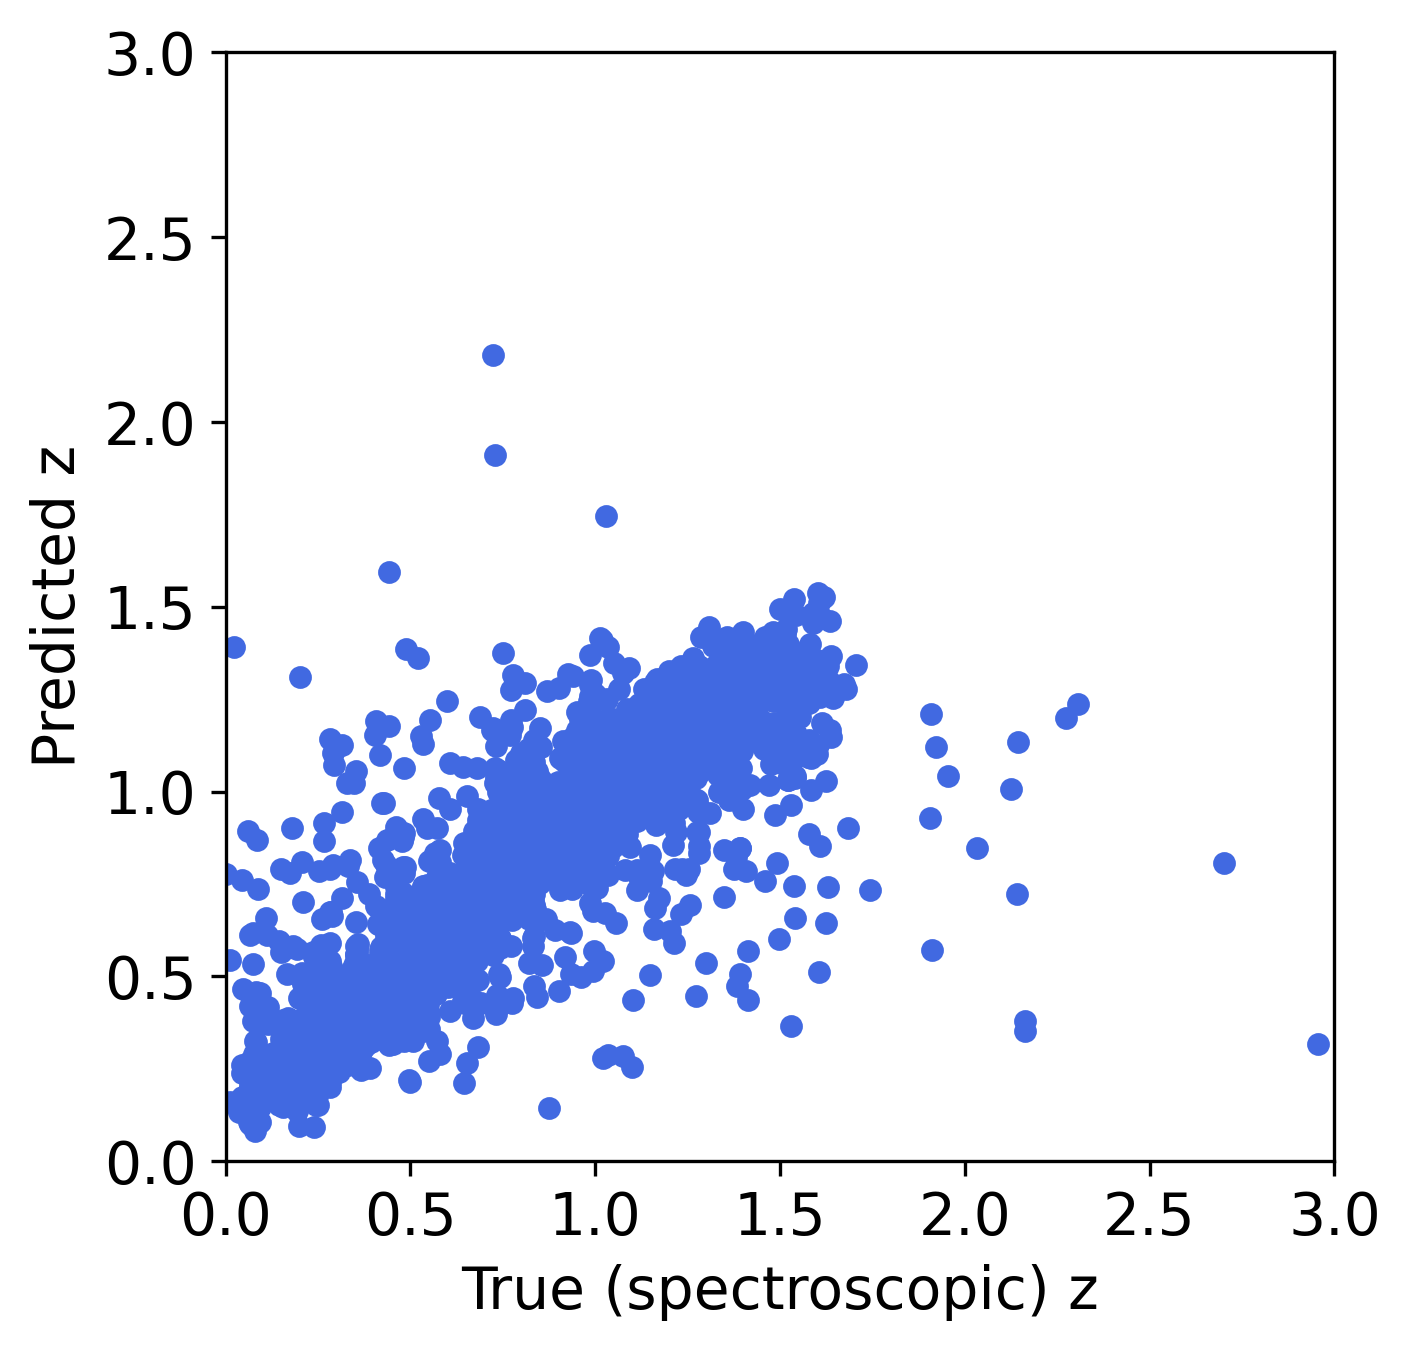

In [134]:
ypred_new = cross_val_predict(model,sel_features,sel_target,cv=cv)
plt.scatter(sel_target,ypred_new, s = 20, c = 'royalblue')
plt.xlabel('True (spectroscopic) z', fontsize=14)
plt.ylabel('Predicted z',fontsize=14)
plt.axis('square')
plt.xlim(0,3)
plt.ylim(0,3)

Ahora se nota más parecido al del paper

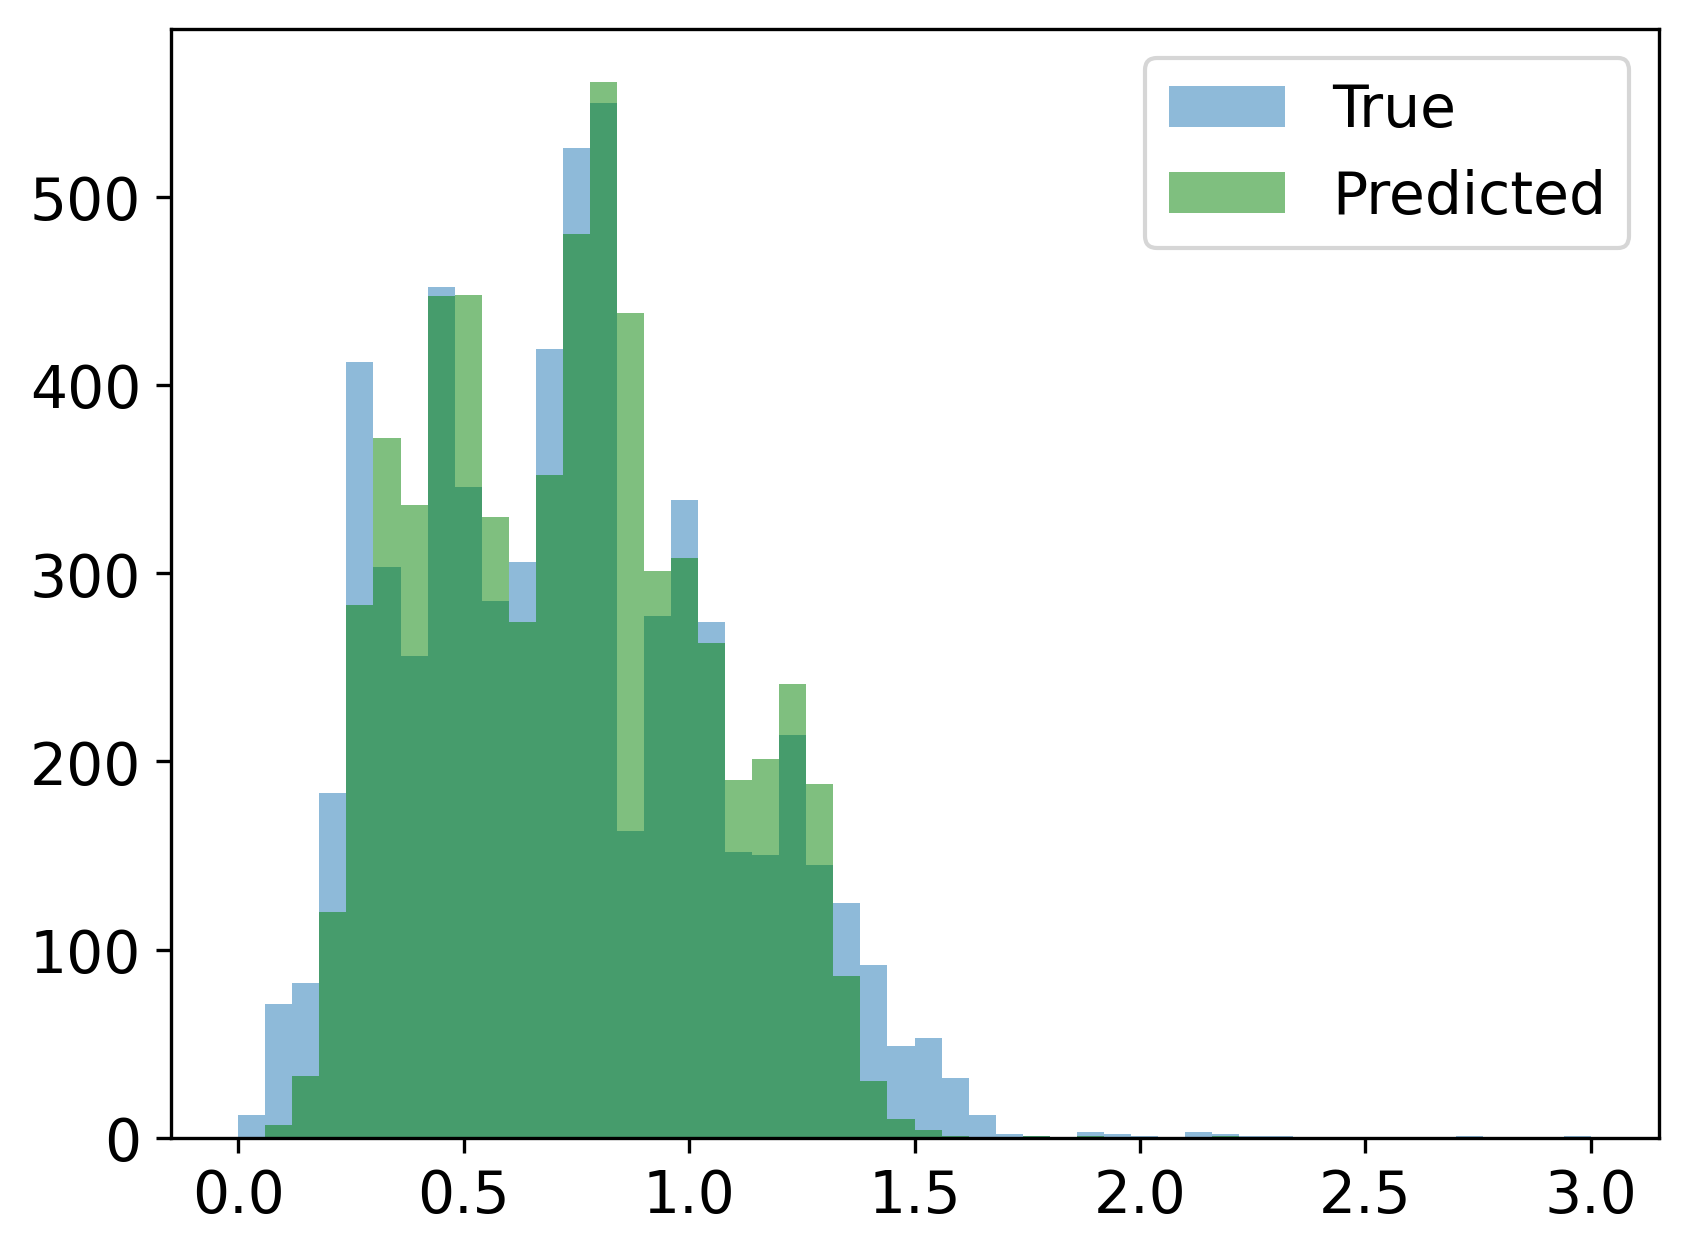

In [139]:
plt.hist(sel_target,bins=50,density=False,alpha=0.5, range = (0,3), label = 'True');
plt.hist(ypred_new,bins=50,density=False,alpha=0.5, range = (0,3), color = 'g', label = 'Predicted');
plt.legend(fontsize=14);

Métricas del paper para el otro caso

In [140]:
#ahora con datos reducidos
import numpy as np
ypred_array_new = np.asarray(ypred_new).ravel() 
T_array_new = np.asarray(sel_target).ravel()
#esto es para verificar 
print("ypred:", ypred_array_new.shape)
print("T:", T_array_new.shape)

ok_z_new = np.abs(ypred_array_new - T_array_new) / (1 + T_array_new)
sigma_nmad_new = 1.48 * np.median(ok_z_new)

eta_new = np.mean(ok_z_new > 0.15)

print("sigma_NMAD=", sigma_nmad_new)
print("eta=", eta_new) #*100

ypred: (6307,)
T: (6307,)
sigma_NMAD= 0.0365451885168859
eta= 0.054542571745679405


Claramente el modelo ahora tanto visualmente como en las métricas definidas por el paper se parece mucho más al de este último, dado que se ha obtenido un sigmaNMAD de 0.0365 y eta de 5.45%, lo que se acerca más tanto al CFHTLS Wide field ugriz and Subaru Y-band photometry con una diferencia de outliers de alrededor 0.61% y de sigmaNMAD de 0.0018, también como al CFHTLS Deep field photometry, donde los outliers se diferencian en un porcentaje de solo alrededor 0.85% y sigmaNMAD de 0.0189. Por lo tanto, al involucrar otras columnas mejoró mucho más el modelo respecto al anterior.

In [141]:
np.random.seed(20)
sel_new = np.random.choice(range(len(ypred_new)), 5000, replace = False) #sample sin reemplazo, sin repeticion
len(np.unique(sel_new))
seld_new = sel_features.iloc[sel_new, :]
selt_new = sel_target.iloc[sel_new]

In [142]:
littlescores_new = cross_validate(model,seld_new,selt_new, cv = KFold(n_splits=5, shuffle=True, random_state=10), return_train_score=True)

/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vec

In [143]:
littlescores_new['test_score'].mean(), littlescores_new['train_score'].mean()

(0.7261426247420343, 0.9622134344139376)

In [144]:
%%time
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, KFold
parameters_new = {
    'min_impurity_decrease': [0.1, 0.5, 0.0],
    'max_features': [None, 4, 2],
    'n_estimators': [50, 100, 200],
    'min_samples_split': [10, 20, 100],
    'max_leaf_nodes': [None, 100, 200]
}
model = RandomForestRegressor(random_state=101)

model = GridSearchCV(model, parameters_new, cv = KFold(n_splits=5, shuffle=True), \
                     verbose = 2, n_jobs = 4, return_train_score=True)
model.fit(seld_new, selt_new.values.ravel())
print("Mejores parámetros:", model.best_params_)
print(f"Mejor R² en validación cruzada: {model.best_score_:.4f}")
print(
    f"R² de entrenamiento: "
    f"{model.cv_results_['mean_train_score'][model.best_index_]:.4f}"
)

Fitting 5 folds for each of 243 candidates, totalling 1215 fits
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=10, n_estimators=50; total time=   0.1s
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=10, n_estimators=100; total time=   0.1s
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=10, n_estimators=200; total time=   0.2s
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=10, n_estimators=200; total time=   0.2s
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=20, n_estimators=100; total time=   0.1s
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=20, n_estimators=200; total time=   0.2s
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=100, n_estimators=50; total time=

In [145]:
scores_new = pd.DataFrame(model.cv_results_)
scoresCV_new = scores_new[['params','mean_test_score','std_test_score','mean_train_score']].sort_values(by = 'mean_test_score', \
                                                    ascending = False)

In [146]:
scoresCV_new

,params,mean_test_score,std_test_score,mean_train_score
101,"{'max_features': 4, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 1...",0.731870,0.073267,0.921914
100,"{'max_features': 4, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 1...",0.730526,0.073960,0.921001
19,"{'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split'...",0.730028,0.069960,0.926444
18,"{'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split'...",0.730022,0.068780,0.923215
20,"{'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split'...",0.729789,0.071227,0.926818
...,...,...,...,...
70,"{'max_features': None, 'max_leaf_nodes': 200, 'min_impurity_decrease': 0.5, 'min_samples_split':...",-0.001636,0.000989,-0.000002
202,"{'max_features': 2, 'max_leaf_nodes': 100, 'min_impurity_decrease': 0.5, 'min_samples_split': 20...",-0.001636,0.000989,-0.000002
67,"{'max_features': None, 'max_leaf_nodes': 200, 'min_impurity_decrease': 0.5, 'min_samples_split':...",-0.001636,0.000989,-0.000002
205,"{'max_features': 2, 'max_leaf_nodes': 100, 'min_impurity_decrease': 0.5, 'min_samples_split': 10...",-0.001636,0.000989,-0.000002



[CV] END max_features=4, max_leaf_nodes=200, min_impurity_decrease=0.5, min_samples_split=20, n_estimators=200; total time=   0.2s
[CV] END max_features=4, max_leaf_nodes=200, min_impurity_decrease=0.5, min_samples_split=20, n_estimators=200; total time=   0.2s
[CV] END max_features=4, max_leaf_nodes=200, min_impurity_decrease=0.5, min_samples_split=100, n_estimators=100; total time=   0.1s
[CV] END max_features=4, max_leaf_nodes=200, min_impurity_decrease=0.5, min_samples_split=100, n_estimators=200; total time=   0.2s
[CV] END max_features=4, max_leaf_nodes=200, min_impurity_decrease=0.0, min_samples_split=10, n_estimators=50; total time=   0.2s
[CV] END max_features=4, max_leaf_nodes=200, min_impurity_decrease=0.0, min_samples_split=10, n_estimators=100; total time=   0.5s
[CV] END max_features=4, max_leaf_nodes=200, min_impurity_decrease=0.0, min_samples_split=10, n_estimators=100; total time=   0.5s
[CV] END max_features=4, max_leaf_nodes=200, min_impurity_decrease=0.0, min_sampl

<h2 style="color:fuchsia; font-family:; text-align:center;font-size:20px">
  ❁۪ ｡˚ Conclusión parte I: Cómo se compara nuestro modelo con el resultado del paper?  ❁۪ ｡˚
</h2>

Los scores mejoraron considerablemente, puesto que antes para el mejor resultado se obtuvo un mean test score de 0.30 y para el nuevo modelo 0.73. Para el std test score también aumentó para el segundo modelo, desde 0.041215 a 0.079564. Y el mean train score aumentó desde 0.65 a 0.92. 

Revisando la sección 7 del paper. Podemos mejorar nuestro modelo aún más? Si se puede mejorar más, debido a la creación e implementación de un nuevo modelo con la mejora identificada

<h2 style="color:fuchsia; font-family:; text-align:center;font-size:17px">
  ❁۪ ｡˚ Nuevo método: Uso de fotometría CFHTLS de catálogo fotométrico 3D-HST con método de restas de magnitudes como nuevos features ❁۪ ｡˚
</h2>

El nuevo método implementado es considerado como una validación adicional a la fotometría MAG APERCOR utilizada previamente para prueba de photo-z usando la fotometría CFHTLS de catálogos fotométricos 3D-HST de Skelton et al. 2014. Donde el paper involucra un accuracy similar a MAG APERCOR photo-z, teniendo también 2% menos de σNMAD y 17% menos de outliers, lo que significa una mejora aún más considerable.

In general, there are two classes of method for calculating the
photometric redshifts. template-fitting method, in which
the redshift is obtained from the best fit to the photometry (in the chi-
squared sense) determined using known template SEDs. The other
is the empirical method, in which a with spectroscopic redshifts is
used to train an empirical relation between photometry and redshift
(typically via machine learning algorithms), and the empirical
relation is then applied to new photometric data to estimate the
redshift. random
forest regression (Breiman 2001) which is included in the PYTHON
package SCIKIT-LEARN (Pedregosa et al. 2011). Random forest
is an ensemble learning method based on decision trees. A simple
decision tree is trained by minimizing the sum of squared errors, and
it tends to fit the noise in the data (i.e. overfitting). The overfitting
results in reduced accuracy when the algorithm applied to new data.
Random forest addresses this problem in two ways. First, a large
number of new samples are created by bootstrapping the original
training sample, and separate decision trees are trained using each
sample. Secondly, instead of all the features (colours in our case),
a random subset of the features may be used at each tree split to
reduce the correlation between the trees. Although overfitting can
occur in individual trees, the effect is reduced by using subsets of
features and averaged out by combining the predictions from all the
trees. In our analysis using a subset of features did not significantly
improve the results, and thus all available features were used at each
split.

A partir del paper el uso de MAG_APERCOR mejora respecto al de MAG_AUTO, porque hay significante reducción de outliers además de que sigma está reducido en datos del paper para el DEEP un 27%. El scatter en delta z es más grande que zspec > 1.4 para ambos mag en ambos sistemas wide y deep area. Sucede eso debido al pequeño número de objetos training en el rango de redshift además de lack de features disponibles en el óptico.

En este caso de mejora por lo que se menciona en el paper, se probó por opción propia con dos archivos distintos para ver las diferencias y cómo resultaba la tendencia entre z phot y zspec, pero al final dado que el paper considera el archivo para deep2, no se usa el del link. Además no calzaba con las mediciones que se proponían.
(Desde la página (link) se descarga el archivo nuevo 3D-HST Terapix Subaru v1.fits para mejorar el modelo:
https://academic.oup.com/mnras/article/488/4/4565/5538813#supplementary-data)
Luego se tenía también que la mejora era la resta de magnitudes, para hacer una definición de nuevos features.

In [541]:
with fits.open('DEEP2_uniq_Terapix_Subaru_v1.fits') as data:
    df = pd.DataFrame(np.array(data[1].data).byteswap().newbyteorder()) 
    #https://numpy.org/doc/2.1/user/byteswapping.html

In [542]:
df.columns

Index(['objno_deep2', 'ra_deep2', 'dec_deep2', 'magb', 'magr', 'magi', 'pgal',
       'sfd_ebv', 'class', 'subclass', 'objname', 'maskname', 'slitname',
       'date', 'mjd', 'z_raw', 'zhelio', 'z_err', 'rchi2', 'dof', 'vdisp',
       'vdisp_err', 'zquality', 'egsflags', 'comment', 'm_b', 'ub_0',
       'ra_cfhtls', 'dec_cfhtls', 'u', 'g', 'r', 'i', 'i2', 'z', 'uerr',
       'gerr', 'rerr', 'ierr', 'i2err', 'zerr', 'u_apercor', 'g_apercor',
       'r_apercor', 'i_apercor', 'i2_apercor', 'z_apercor', 'uerr_aper',
       'gerr_aper', 'rerr_aper', 'ierr_aper', 'i2err_aper', 'zerr_aper',
       'uerr_apercor', 'gerr_apercor', 'rerr_apercor', 'ierr_apercor',
       'i2err_apercor', 'zerr_apercor', 'r_radius_arcsec', 'u(sexflag)',
       'g(sexflag)', 'r(sexflag)', 'i(sexflag)', 'i2(sexflag)', 'z(sexflag)',
       'flag_cfhtls', 'cfhtls_source', 'ra_subaru', 'dec_subaru', 'y', 'yerr',
       'y_apercor', 'yerr_aper', 'yerr_apercor', 'y(sexflag)',
       'y_radius_arcsec', 'subaru_source'],
 

In [543]:
#como en el paper se mencionan condiciones para el caso de 3DHST
#además se menciona
#The five colours u− g, g− r, r− i, i− z, z− y, and i-band magnitude are used as the input (duda).

In [479]:
mags = df[['u_apercor', 'g_apercor', 'r_apercor', 'i_apercor', 'z_apercor','y_apercor','subaru_source','cfhtls_source','zquality']]

In [481]:
#haciendo lo mismo que antes
#zquality - solo usa objetos con medición de redshift de buena calidad
mags = mags[mags['zquality'] >= 3]
mags.shape

(16857, 9)

In [482]:
#selecciona objetos con datos del catálogo cfhtls deep photometric data
mags = mags[mags['cfhtls_source'] == 0]
mags.shape

(10671, 9)

In [488]:
mags = mags[mags > -10].dropna()
mags.shape

(6307, 9)

In [489]:
mags = mags[mags < 90].dropna()
mags.shape

(6307, 9)

In [547]:
sel_features_hst = mags[['u_apercor', 'g_apercor', 'r_apercor', 'i_apercor', 'z_apercor','y_apercor']]
sel_features_hst.head()
sel_target = T.loc[sel_features.index]

In [548]:
#duda, porque se quiere hacer con resta de magnitudes 
#df_grism = df_grism.copy()
#df_grism["u-g"] = df_grism["u_apercor"] - df_grism["g_apercor"]
#df_grism["g-r"] = df_grism["g_apercor"] - df_grism["r_apercor"]
#df_grism["r-i"] = df_grism["r_apercor"] - df_grism["i_apercor"]
#df_grism["i-z"] = df_grism["i_apercor"] - df_grism["z_apercor"]
#df_grism["z-y"] = df_grism["z_apercor"] - df_grism["y_apercor"]
#features = ["u-g", "g-r", "r-i", "i-z", "z-y", "i_apercor"]
#target = "z_spec"
#data = df_grism[features + [target]].copy()
#Xhst = data[features]
#sel_target_hst = data[target]

In [549]:
Xrestado = pd.DataFrame({
    'u-g': sel_features_hst['u_apercor'] - sel_features_hst['g_apercor'],
    'g-r': sel_features_hst['g_apercor'] - sel_features_hst['r_apercor'],
    'r-i': sel_features_hst['r_apercor'] - sel_features_hst['i_apercor'],
    'i-z': sel_features_hst['i_apercor'] - sel_features_hst['z_apercor'],
    'z-y': sel_features_hst['z_apercor'] - sel_features_hst['y_apercor'],
    'i':   sel_features_hst['i_apercor'],
})

In [550]:
Xrestado.head()

,u-g,g-r,r-i,i-z,z-y,i
1251,0.264811,0.457447,0.611094,0.385268,0.196675,22.911041
1253,0.572953,0.992500,1.049899,0.567258,0.055055,21.873752
1261,1.900066,1.508042,0.677430,0.326138,0.048586,20.788420
1271,0.190411,0.447442,0.685087,0.216758,-0.123037,23.206102
1272,0.253733,0.412146,0.740102,0.425541,0.250175,22.235199


In [551]:
#definiendo el modelo igual
modelhst = RandomForestRegressor()
modelhst.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 1.0,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

In [555]:
modelhst = RandomForestRegressor()

In [556]:
modelhst.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 1.0,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

In [557]:
cvhst = KFold(n_splits=5, shuffle=True, random_state=101) #para la clasificación

In [558]:
%%time
scores_hst = cross_validate(modelhst,Xrestado,sel_target,cv=cvhst,scoring="r2",return_train_score=True)

/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vec

CPU times: user 5.28 s, sys: 30.4 ms, total: 5.31 s
Wall time: 5.31 s


In [559]:
df_results_hst = pd.DataFrame({"Fold": range(1, 6),"R2_train": scores_hst["train_score"],"R2_test": scores_hst["test_score"]})
display(df_results_hst.round(4))
#Calculando el promedio y la desviación estándar de las métricas obtenidas.
print(f"R² entrenamiento: {scores_hst['train_score'].mean():.4f} "
      f"± {scores_hst['train_score'].std():.4f}")
print(f"R² prueba:        {scores_hst['test_score'].mean():.4f} "
      f"± {scores_hst['test_score'].std():.4f}")

,Fold,R2_train,R2_test
0,1,0.9722,0.8100
1,2,0.9745,0.7747
2,3,0.9731,0.7455
3,4,0.9741,0.7843
4,5,0.9690,0.8777


R² entrenamiento: 0.9726 ± 0.0020
R² prueba:        0.7984 ± 0.0447


In [560]:
scores_hst

{'fit_time': array([0.98441005, 0.99142408, 0.97764874, 0.99210596, 1.00212479]),
 'score_time': array([0.01854992, 0.01940918, 0.01941609, 0.0193212 , 0.01908708]),
 'test_score': array([0.8099825 , 0.77472884, 0.74554627, 0.78425993, 0.87772817]),
 'train_score': array([0.97224721, 0.9744904 , 0.97306385, 0.97408757, 0.9689739 ])}

In [561]:
ypred_hst = cross_val_predict(modelhst,Xrestado,sel_target,cv=cvhst)

/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vec

(0.0, 3.0)

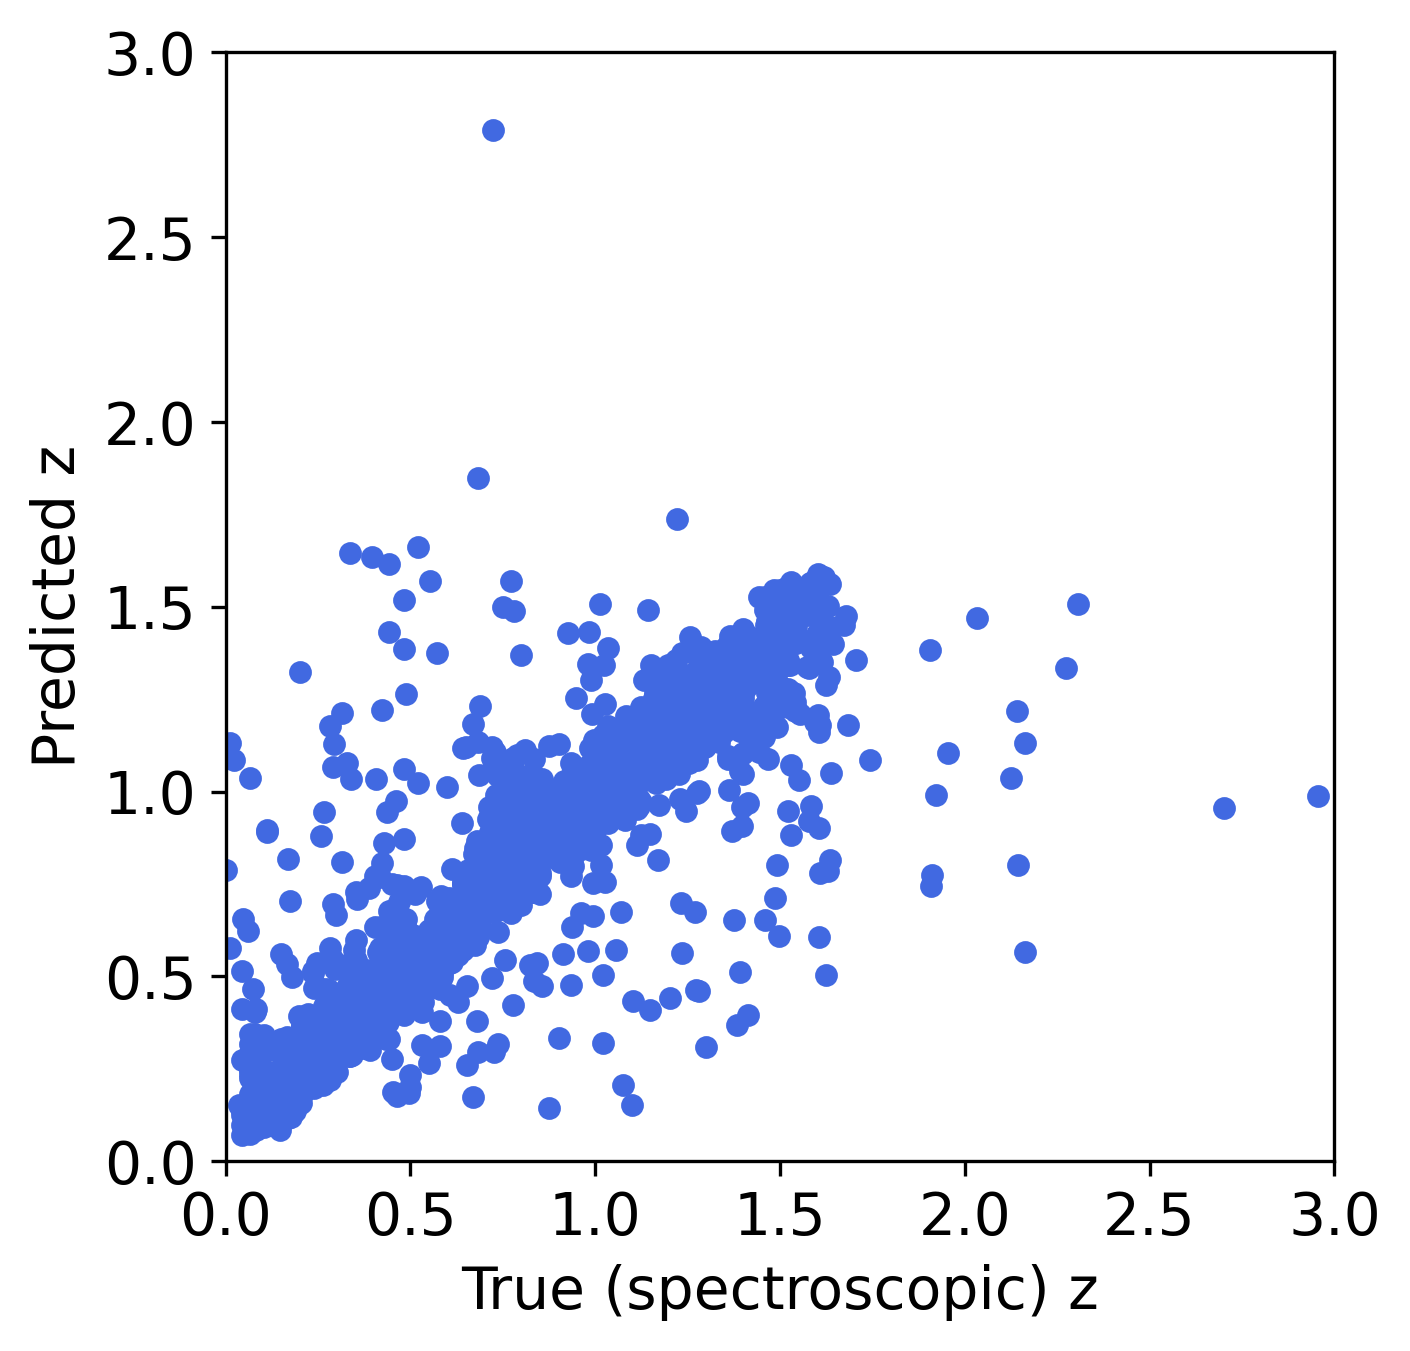

In [562]:
plt.scatter(sel_target,ypred_hst, s = 20, c = 'royalblue')
plt.xlabel('True (spectroscopic) z', fontsize=14)
plt.ylabel('Predicted z',fontsize=14)
plt.axis('square')
plt.xlim(0,3)
plt.ylim(0,3)

Ahora el modelo ha mejorado mucho más con la aplicación de restas de magnitudes

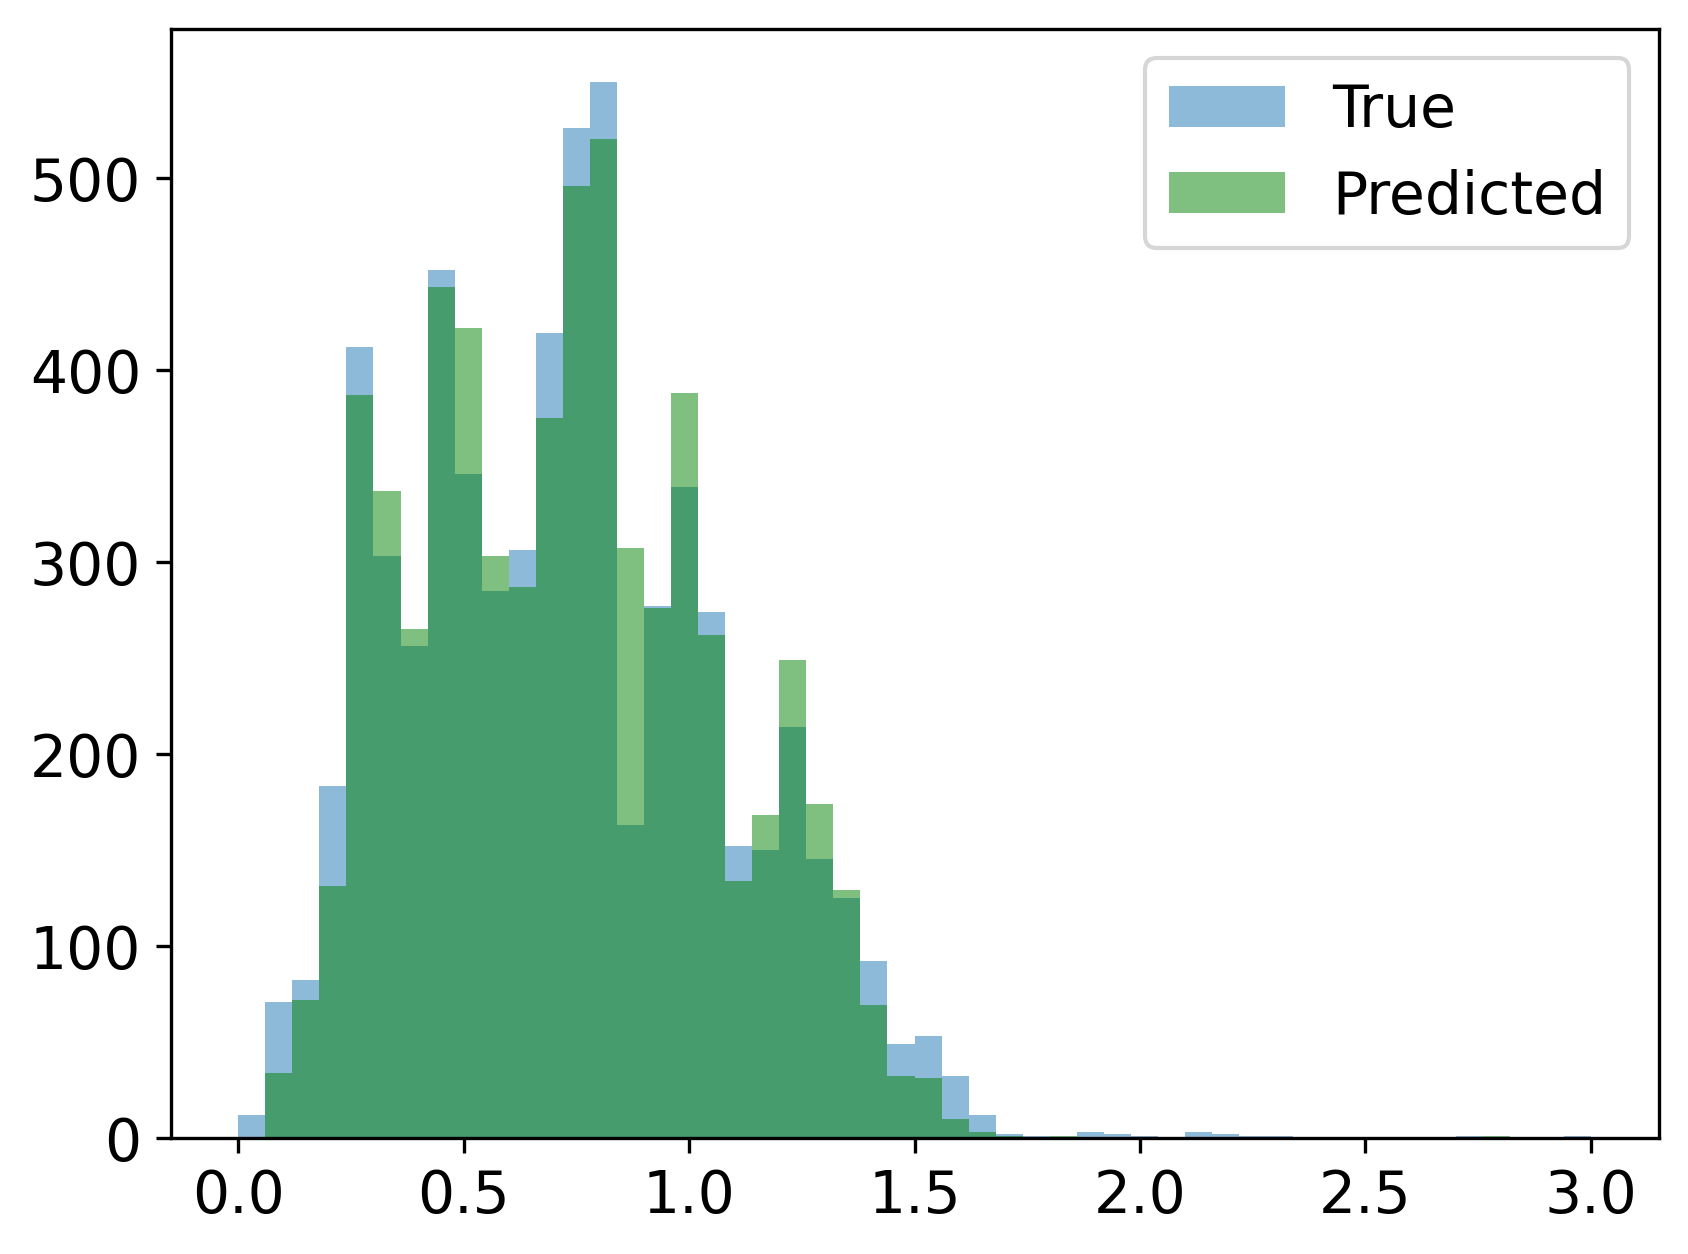

In [564]:
plt.hist(sel_target,bins=50,density=False,alpha=0.5, range = (0,3), label = 'True');
plt.hist(ypred_hst,bins=50,density=False,alpha=0.5, range = (0,3), color = 'g', label = 'Predicted');
plt.legend(fontsize=14);

In [565]:
#para los datos reducidos
ypred_array_hst = np.asarray(ypred_hst).ravel() 
T_array_hst= np.asarray(sel_target).ravel()
#esto es para verificar 
print("ypred:", ypred_array_hst.shape)
print("T:", T_array_hst.shape)
ok_z_hst = np.abs(ypred_array_hst - T_array_hst) / (1 + T_array_hst)
sigma_nmad_hst = 1.48 * np.median(ok_z_hst)
eta_hst = np.mean(ok_z_hst > 0.15)
print("sigma_NMAD=", sigma_nmad_hst)
print("eta=", eta_hst*100) 

ypred: (6307,)
T: (6307,)
sigma_NMAD= 0.01627616759539242
eta= 3.551609322974473


Ahora sigmaNMAD ha mejorado tanto como los outliers, los cuales disminuyeron igualmente a aproximadamente 3.55%. 

In [566]:
np.random.seed(20)
sel_hst = np.random.choice(range(len(ypred_hst)), 5000, replace = False) #sample sin reemplazo, sin repeticion
len(np.unique(sel_hst))

5000

In [567]:
seld_hst= Xrestado.iloc[sel_hst, :]
selt_hst = sel_target.iloc[sel_hst]

In [568]:
littlescores_hst = cross_validate(modelhst,seld_hst,selt_hst, cv = KFold(n_splits=5, shuffle=True, random_state=10), return_train_score=True)
littlescores_hst['test_score'].mean(), littlescores_hst['train_score'].mean()

/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vec

(0.7978911347113983, 0.9706390788647703)

In [569]:
%%time
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, KFold
parameters_hst = {
    'min_impurity_decrease': [0.1, 0.5, 0.0],
    'max_features': [None, 4, 2],
    'n_estimators': [50, 100, 200],
    'min_samples_split': [10, 20, 100],
    'max_leaf_nodes': [None, 100, 200]
}
modelhst = RandomForestRegressor(random_state=101)
modelhst = GridSearchCV(modelhst, parameters_hst, cv = KFold(n_splits=5, shuffle=True), \
                     verbose = 2, n_jobs = 4, return_train_score=True)
modelhst.fit(seld_hst, selt_hst.values.ravel())
print("Mejores parámetros:", modelhst.best_params_)
print(f"Mejor R² en validación cruzada: {modelhst.best_score_:.4f}")
print(
    f"R² de entrenamiento: "
    f"{modelhst.cv_results_['mean_train_score'][modelhst.best_index_]:.4f}"
)

Fitting 5 folds for each of 243 candidates, totalling 1215 fits
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=10, n_estimators=50; total time=   0.1s
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=10, n_estimators=100; total time=   0.1s
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=10, n_estimators=200; total time=   0.2s
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=20, n_estimators=50; total time=   0.1s
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=20, n_estimators=50; total time=   0.1s
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=20, n_estimators=100; total time=   0.1s
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=20, n_estimators=100; total time=  

In [570]:
scores_hst = pd.DataFrame(modelhst.cv_results_)

In [571]:
scoresCV_hst= scores_hst[['params','mean_test_score','std_test_score','mean_train_score']].sort_values(by = 'mean_test_score', \
                                                    ascending = False)
scoresCV_hst

,params,mean_test_score,std_test_score,mean_train_score
234,"{'max_features': 2, 'max_leaf_nodes': 200, 'min_impurity_decrease': 0.0, 'min_samples_split': 10...",0.810197,0.058711,0.930624
182,"{'max_features': 2, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 1...",0.809787,0.061169,0.937979
235,"{'max_features': 2, 'max_leaf_nodes': 200, 'min_impurity_decrease': 0.0, 'min_samples_split': 10...",0.809744,0.059005,0.933329
236,"{'max_features': 2, 'max_leaf_nodes': 200, 'min_impurity_decrease': 0.0, 'min_samples_split': 10...",0.809551,0.059294,0.933448
181,"{'max_features': 2, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 1...",0.808371,0.059374,0.936196
...,...,...,...,...
70,"{'max_features': None, 'max_leaf_nodes': 200, 'min_impurity_decrease': 0.5, 'min_samples_split':...",-0.001636,0.000989,-0.000002
202,"{'max_features': 2, 'max_leaf_nodes': 100, 'min_impurity_decrease': 0.5, 'min_samples_split': 20...",-0.001636,0.000989,-0.000002
67,"{'max_features': None, 'max_leaf_nodes': 200, 'min_impurity_decrease': 0.5, 'min_samples_split':...",-0.001636,0.000989,-0.000002
205,"{'max_features': 2, 'max_leaf_nodes': 100, 'min_impurity_decrease': 0.5, 'min_samples_split': 10...",-0.001636,0.000989,-0.000002



[CV] END max_features=2, max_leaf_nodes=100, min_impurity_decrease=0.1, min_samples_split=10, n_estimators=50; total time=   0.0s
[CV] END max_features=2, max_leaf_nodes=100, min_impurity_decrease=0.1, min_samples_split=10, n_estimators=50; total time=   0.0s
[CV] END max_features=2, max_leaf_nodes=100, min_impurity_decrease=0.1, min_samples_split=10, n_estimators=50; total time=   0.1s
[CV] END max_features=2, max_leaf_nodes=100, min_impurity_decrease=0.1, min_samples_split=10, n_estimators=100; total time=   0.1s
[CV] END max_features=2, max_leaf_nodes=100, min_impurity_decrease=0.1, min_samples_split=10, n_estimators=100; total time=   0.1s
[CV] END max_features=2, max_leaf_nodes=100, min_impurity_decrease=0.1, min_samples_split=10, n_estimators=100; total time=   0.1s
[CV] END max_features=2, max_leaf_nodes=100, min_impurity_decrease=0.1, min_samples_split=10, n_estimators=100; total time=   0.1s
[CV] END max_features=2, max_leaf_nodes=100, min_impurity_decrease=0.1, min_samples_s

<h2 style="color:fuchsia; font-family:; text-align:center;font-size:20px">
  ❁۪ ｡˚ Conclusión parte II y final: Cómo se comparan los modelos consecuentes al aplicar nuevos métodos?  ❁۪ ｡˚
</h2>

De acuerdo a lo obtenido, tanto R2 como los scores han mejorado con la inclusión de la diferencia de magnitudes como nuevo método, en vez de solo usar las magnitudes directas. Ahora el mejor mean test score es 0.81, la std es 0.05 y el mejor mean train score resulta 0.93. 

A medida que se iban mejorando los datos, a través de 3 modelos, se obtuvo al principio un R2 de entrenamiento de aproximadamente 0.8760 +/- 0.0011, y un R2 de 0.3138 +/- 0.0146. Con un valor mejor de scores, para mean test, std test y mean train, 0.30, 0.04 y 0.65, respectivamente. Luego para el 2do modelo involucrando más características y rangos considerables de acuerdo al paper, la métrica R2 mejora considerablemente tanto para el train como prueba, con 0.9636 +/- 0.0030 y 0.7449 +/- 0.0747, respectivamente. Además mejoran los test y train score, para mean, se tiene 0.73 y 0.92. Ya en el último modelo, R2 mejora a 0.9726 +/- 0.0020 para el train y para prueba 0.7984 +/- 0.0447, además el mean test score es 0.81 y el mean train score 0.93. Los outliers también mejoran mucho, siendo en el último modelo una reducción de ellos a alrededor de 3.55 %. Lo que resulta bastante mejor comparado con los del obtenido para el paper considerando que en este se utiliza el modelo Deep field para MAG_APERCOR, pues el outlier % es 4.54% y sigma también disminuye en nuestro modelo a 0.0162, lo que en el paper aparece como 0.0174.